Load the dataset

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/content/Mobilephone_data_final.csv")

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

display(df.head())
display(df.describe())


Dataset Shape: (1359, 22)

Column Names:
['Sr. No.', 'Name', 'Brand', 'Model', 'Battery capacity (mAh)', 'Screen size (inches)', 'Touchscreen', 'Resolution x', 'Resolution y', 'Processor', 'RAM (MB)', 'Internal storage (GB)', 'Rear camera', 'Front camera', 'Operating system', 'Wi-Fi', 'Bluetooth', 'GPS', 'Number of SIMs', '3G', '4G/ LTE', 'Price']

Missing Values:
Sr. No.                   0
Name                      0
Brand                     0
Model                     0
Battery capacity (mAh)    0
Screen size (inches)      0
Touchscreen               0
Resolution x              0
Resolution y              0
Processor                 0
RAM (MB)                  0
Internal storage (GB)     0
Rear camera               0
Front camera              0
Operating system          0
Wi-Fi                     0
Bluetooth                 0
GPS                       0
Number of SIMs            0
3G                        0
4G/ LTE                   0
Price                     0
dtype: int64


,Sr. No.,Name,Brand,Model,Battery capacity (mAh),Screen size (inches),Touchscreen,Resolution x,Resolution y,Processor,...,Rear camera,Front camera,Operating system,Wi-Fi,Bluetooth,GPS,Number of SIMs,3G,4G/ LTE,Price
0,0,OnePlus 7T Pro McLaren Edition,OnePlus,7T Pro McLaren Edition,4085,6.67,Yes,1440,3120,8,...,48.0,16.0,Android,Yes,Yes,Yes,2,Yes,Yes,58998
1,1,Realme X2 Pro,Realme,X2 Pro,4000,6.50,Yes,1080,2400,8,...,64.0,16.0,Android,Yes,Yes,Yes,2,Yes,Yes,27999
2,2,iPhone 11 Pro Max,Apple,iPhone 11 Pro Max,3969,6.50,Yes,1242,2688,6,...,12.0,12.0,iOS,Yes,Yes,Yes,2,Yes,Yes,106900
3,3,iPhone 11,Apple,iPhone 11,3110,6.10,Yes,828,1792,6,...,12.0,12.0,iOS,Yes,Yes,Yes,2,Yes,Yes,62900
4,4,LG G8X ThinQ,LG,G8X ThinQ,4000,6.40,Yes,1080,2340,8,...,12.0,32.0,Android,Yes,Yes,Yes,1,No,No,49990


,Sr. No.,Battery capacity (mAh),Screen size (inches),Resolution x,Resolution y,Processor,RAM (MB),Internal storage (GB),Rear camera,Front camera,Number of SIMs,Price
count,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000
mean,679.000000,2938.489330,5.291310,811.543046,1490.777778,5.551141,2488.777778,30.654864,12.070199,7.037969,1.833701,11465.825607
std,392.453819,873.514133,0.671357,270.707271,557.780120,2.196562,1664.440386,36.950241,8.948337,6.295448,0.374457,13857.497077
min,0.000000,1010.000000,2.400000,240.000000,320.000000,1.000000,64.000000,0.064000,0.000000,0.000000,1.000000,494.000000
25%,339.500000,2300.000000,5.000000,720.000000,1280.000000,4.000000,1000.000000,8.000000,8.000000,2.000000,2.000000,4763.500000
50%,679.000000,3000.000000,5.200000,720.000000,1280.000000,4.000000,2000.000000,16.000000,12.200000,5.000000,2.000000,6999.000000
75%,1018.500000,3500.000000,5.700000,1080.000000,1920.000000,8.000000,3000.000000,32.000000,13.000000,8.000000,2.000000,11999.000000
max,1358.000000,6000.000000,7.300000,2160.000000,3840.000000,10.000000,12000.000000,512.000000,108.000000,48.000000,3.000000,174990.000000


Preprocessing and Cleaning of Dataset

In [2]:

# Remove serial number and descriptive identifiers
df = df.drop(
    columns=["Sr. No.", "Name", "Model"],
    errors="ignore"
)

# Remove duplicate rows, if any
df = df.drop_duplicates()

# Confirm data quality
print("Dataset Shape After Cleaning:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

display(df.head())


Dataset Shape After Cleaning: (1358, 19)
Missing Values: 0
Duplicate Rows: 0


,Brand,Battery capacity (mAh),Screen size (inches),Touchscreen,Resolution x,Resolution y,Processor,RAM (MB),Internal storage (GB),Rear camera,Front camera,Operating system,Wi-Fi,Bluetooth,GPS,Number of SIMs,3G,4G/ LTE,Price
0,OnePlus,4085,6.67,Yes,1440,3120,8,12000,256.0,48.0,16.0,Android,Yes,Yes,Yes,2,Yes,Yes,58998
1,Realme,4000,6.50,Yes,1080,2400,8,6000,64.0,64.0,16.0,Android,Yes,Yes,Yes,2,Yes,Yes,27999
2,Apple,3969,6.50,Yes,1242,2688,6,4000,64.0,12.0,12.0,iOS,Yes,Yes,Yes,2,Yes,Yes,106900
3,Apple,3110,6.10,Yes,828,1792,6,4000,64.0,12.0,12.0,iOS,Yes,Yes,Yes,2,Yes,Yes,62900
4,LG,4000,6.40,Yes,1080,2340,8,6000,128.0,12.0,32.0,Android,Yes,Yes,Yes,1,No,No,49990


EDA

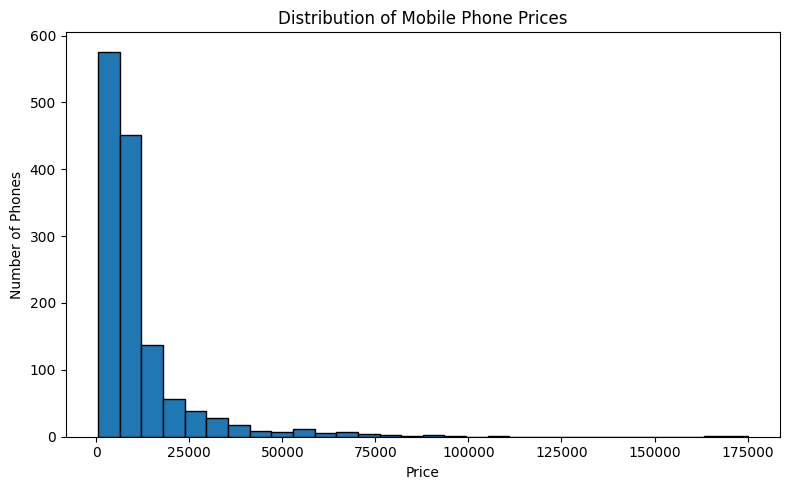

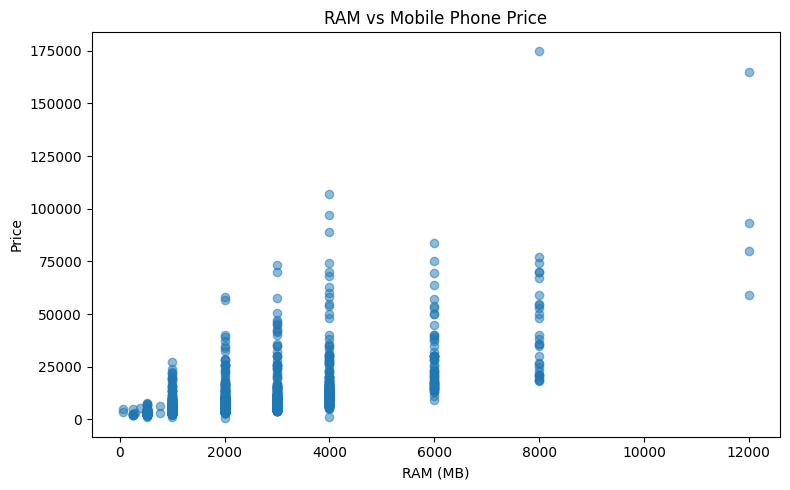

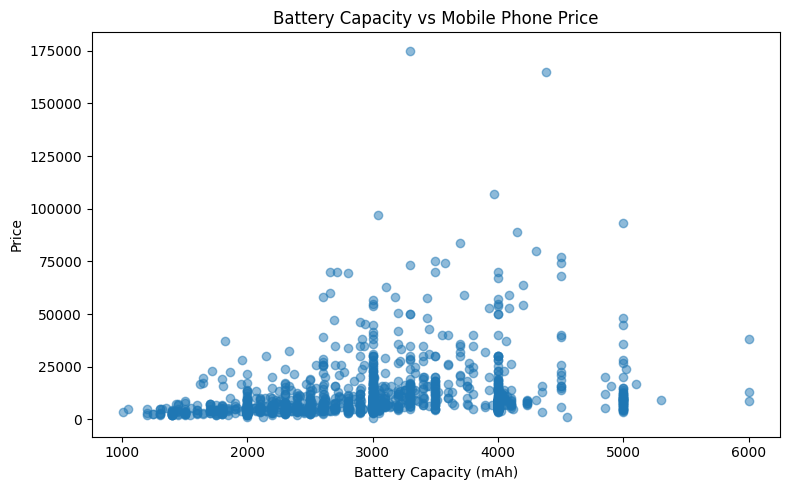

In [3]:

plt.figure(figsize=(8, 5))
plt.hist(df["Price"], bins=30, edgecolor="black")
plt.title("Distribution of Mobile Phone Prices")
plt.xlabel("Price")
plt.ylabel("Number of Phones")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(df["RAM (MB)"], df["Price"], alpha=0.5)
plt.title("RAM vs Mobile Phone Price")
plt.xlabel("RAM (MB)")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(
    df["Battery capacity (mAh)"],
    df["Price"],
    alpha=0.5
)
plt.title("Battery Capacity vs Mobile Phone Price")
plt.xlabel("Battery Capacity (mAh)")
plt.ylabel("Price")
plt.tight_layout()
plt.show()


Prepare Features and Target

In [4]:

from sklearn.model_selection import train_test_split

X = df.drop(columns=["Price"])
y = df["Price"]

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical Features:", categorical_features)
print("Numerical Features:", numerical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))


Categorical Features: ['Brand', 'Touchscreen', 'Operating system', 'Wi-Fi', 'Bluetooth', 'GPS', '3G', '4G/ LTE']
Numerical Features: ['Battery capacity (mAh)', 'Screen size (inches)', 'Resolution x', 'Resolution y', 'Processor', 'RAM (MB)', 'Internal storage (GB)', 'Rear camera', 'Front camera', 'Number of SIMs']

Training Samples: 1086
Testing Samples: 272


Encode categorical features and scale numerical features

In [5]:

from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Encode categorical columns
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_cat = encoder.fit_transform(X_train[categorical_features])
X_test_cat = encoder.transform(X_test[categorical_features])

encoded_columns = encoder.get_feature_names_out(categorical_features)

X_train_cat = pd.DataFrame(
    X_train_cat,
    columns=encoded_columns,
    index=X_train.index
)

X_test_cat = pd.DataFrame(
    X_test_cat,
    columns=encoded_columns,
    index=X_test.index
)

# Scale numerical columns
scaler = StandardScaler()

X_train_num = pd.DataFrame(
    scaler.fit_transform(X_train[numerical_features]),
    columns=numerical_features,
    index=X_train.index
)

X_test_num = pd.DataFrame(
    scaler.transform(X_test[numerical_features]),
    columns=numerical_features,
    index=X_test.index
)

# Combine numerical and categorical features
X_train_processed = pd.concat(
    [X_train_num, X_train_cat], axis=1
)

X_test_processed = pd.concat(
    [X_test_num, X_test_cat], axis=1
)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)


Training shape: (1086, 101)
Testing shape: (272, 101)


Multiple Linear Regression

In [6]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

lr_model = LinearRegression()
lr_model.fit(X_train_processed, y_train)

lr_predictions = lr_model.predict(X_test_processed)

lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_mse = mean_squared_error(y_test, lr_predictions)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_test, lr_predictions)

print("Multiple Linear Regression")
print("MAE:", lr_mae)
print("MSE:", lr_mse)
print("RMSE:", lr_rmse)
print("R² Score:", lr_r2)


Multiple Linear Regression
MAE: 4855.8292214736475
MSE: 77446194.45469964
RMSE: 8800.351950615364
R² Score: 0.7070911858528337


Ridge Regression

In [7]:

from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_processed, y_train)

ridge_predictions = ridge_model.predict(X_test_processed)

ridge_mae = mean_absolute_error(y_test, ridge_predictions)
ridge_mse = mean_squared_error(y_test, ridge_predictions)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test, ridge_predictions)

print("Ridge Regression")
print("MAE:", ridge_mae)
print("MSE:", ridge_mse)
print("RMSE:", ridge_rmse)
print("R² Score:", ridge_r2)


Ridge Regression
MAE: 4856.341567402083
MSE: 76900124.75614454
RMSE: 8769.271620616193
R² Score: 0.7091564729721257


Lasso Regression

In [8]:

from sklearn.linear_model import Lasso

lasso_model = Lasso(alpha=1.0, max_iter=20000)
lasso_model.fit(X_train_processed, y_train)

lasso_predictions = lasso_model.predict(X_test_processed)

lasso_mae = mean_absolute_error(y_test, lasso_predictions)
lasso_mse = mean_squared_error(y_test, lasso_predictions)
lasso_rmse = np.sqrt(lasso_mse)
lasso_r2 = r2_score(y_test, lasso_predictions)

print("Lasso Regression")
print("MAE:", lasso_mae)
print("MSE:", lasso_mse)
print("RMSE:", lasso_rmse)
print("R² Score:", lasso_r2)


Lasso Regression
MAE: 4825.109594245998
MSE: 77560858.61154678
RMSE: 8806.864289379437
R² Score: 0.7066575151935617


Decision Tree Regression

In [9]:

from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

dt_model.fit(X_train_processed, y_train)
dt_predictions = dt_model.predict(X_test_processed)

dt_mae = mean_absolute_error(y_test, dt_predictions)
dt_mse = mean_squared_error(y_test, dt_predictions)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test, dt_predictions)

print("Decision Tree Regression")
print("MAE:", dt_mae)
print("MSE:", dt_mse)
print("RMSE:", dt_rmse)
print("R² Score:", dt_r2)


Decision Tree Regression
MAE: 4659.035810253962
MSE: 134417733.88266805
RMSE: 11593.866218077043
R² Score: 0.49161944871350005


Random Forest

In [10]:

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)
rf_predictions = rf_model.predict(X_test_processed)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_mse = mean_squared_error(y_test, rf_predictions)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Regression")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R² Score:", rf_r2)


Random Forest Regression
MAE: 3670.0878027716262
MSE: 83724416.68388624
RMSE: 9150.104736224948
R² Score: 0.6833463570584495


Bagging

In [11]:

from sklearn.ensemble import BaggingRegressor

bagging_model = BaggingRegressor(
    estimator=DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ),
    n_estimators=30,
    random_state=42,
    n_jobs=-1
)

bagging_model.fit(X_train_processed, y_train)
bagging_predictions = bagging_model.predict(X_test_processed)

bagging_mae = mean_absolute_error(y_test, bagging_predictions)
bagging_mse = mean_squared_error(y_test, bagging_predictions)
bagging_rmse = np.sqrt(bagging_mse)
bagging_r2 = r2_score(y_test, bagging_predictions)

print("Bagging Regression")
print("MAE:", bagging_mae)
print("MSE:", bagging_mse)
print("RMSE:", bagging_rmse)
print("R² Score:", bagging_r2)


Bagging Regression
MAE: 3768.399389523797
MSE: 83582267.25695755
RMSE: 9142.333797065034
R² Score: 0.6838839796022885


Comparision Table

In [12]:

results_df = pd.DataFrame([
    {"Model": "Multiple Linear Regression", "MAE": lr_mae, "MSE": lr_mse, "RMSE": lr_rmse, "R2 Score": lr_r2},
    {"Model": "Ridge Regression", "MAE": ridge_mae, "MSE": ridge_mse, "RMSE": ridge_rmse, "R2 Score": ridge_r2},
    {"Model": "Lasso Regression", "MAE": lasso_mae, "MSE": lasso_mse, "RMSE": lasso_rmse, "R2 Score": lasso_r2},
    {"Model": "Decision Tree", "MAE": dt_mae, "MSE": dt_mse, "RMSE": dt_rmse, "R2 Score": dt_r2},
    {"Model": "Random Forest", "MAE": rf_mae, "MSE": rf_mse, "RMSE": rf_rmse, "R2 Score": rf_r2},
    {"Model": "Bagging Regression", "MAE": bagging_mae, "MSE": bagging_mse, "RMSE": bagging_rmse, "R2 Score": bagging_r2}
]).sort_values("RMSE")

display(results_df.round(2))

print("Best model:", results_df.iloc[0]["Model"])


,Model,MAE,MSE,RMSE,R2 Score
1,Ridge Regression,4856.34,7.690012e+07,8769.27,0.71
0,Multiple Linear Regression,4855.83,7.744619e+07,8800.35,0.71
2,Lasso Regression,4825.11,7.756086e+07,8806.86,0.71
5,Bagging Regression,3768.40,8.358227e+07,9142.33,0.68
4,Random Forest,3670.09,8.372442e+07,9150.10,0.68
3,Decision Tree,4659.04,1.344177e+08,11593.87,0.49


Best model: Ridge Regression


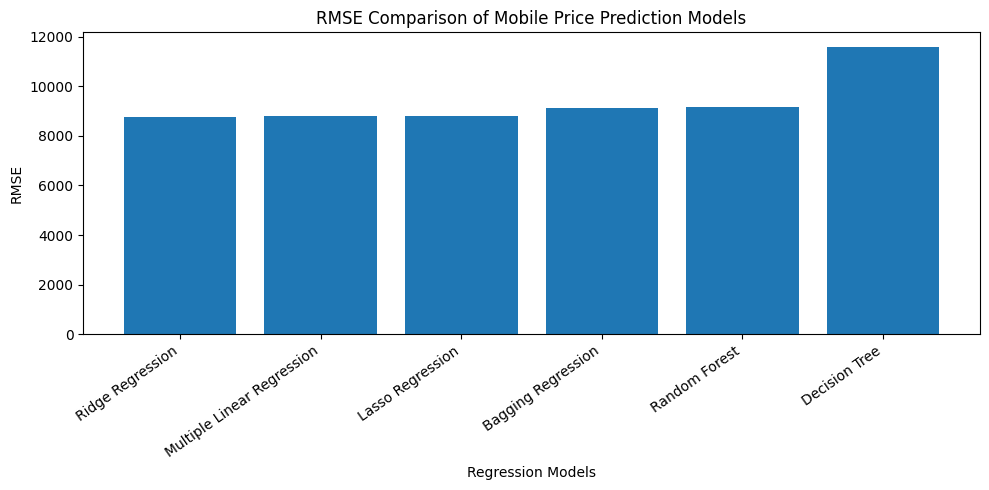

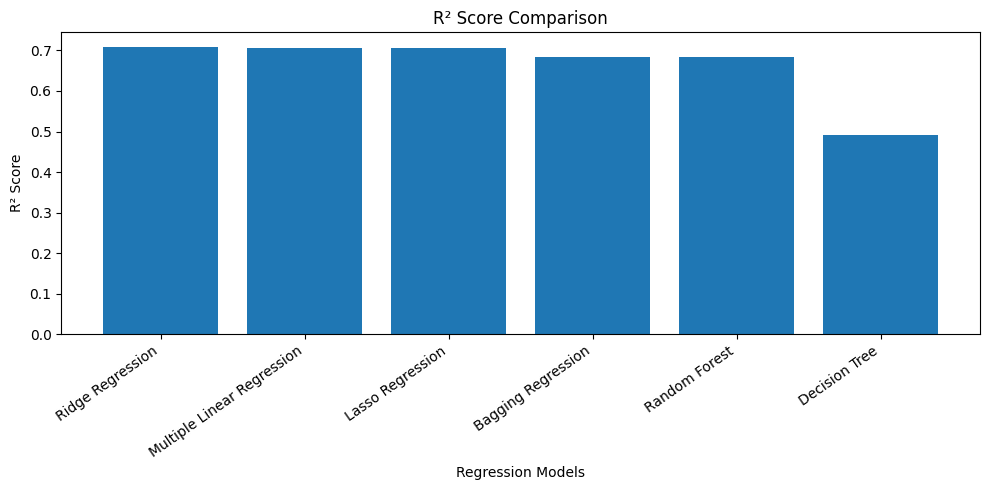

In [13]:

import matplotlib.pyplot as plt

# RMSE comparison
plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.title("RMSE Comparison of Mobile Price Prediction Models")
plt.xlabel("Regression Models")
plt.ylabel("RMSE")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# R2 score comparison
plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["R2 Score"])
plt.title("R² Score Comparison")
plt.xlabel("Regression Models")
plt.ylabel("R² Score")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


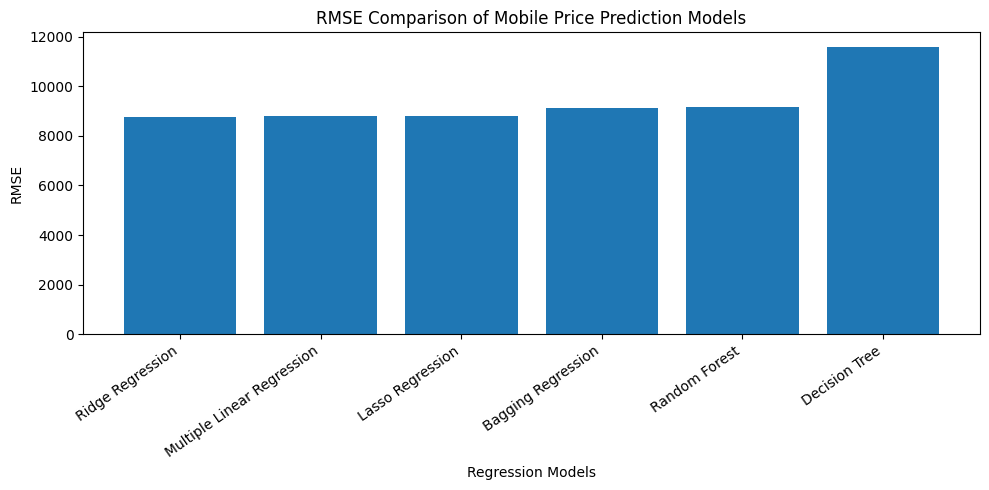

In [14]:

plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.title("RMSE Comparison of Mobile Price Prediction Models")
plt.xlabel("Regression Models")
plt.ylabel("RMSE")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


In [15]:
# Display model comparison
results_df = results_df.sort_values(by="RMSE").reset_index(drop=True)

display(results_df)

# Select the model with the lowest RMSE
best_model_name = results_df.loc[0, "Model"]

print("Best Model based on RMSE:", best_model_name)
print("Lowest RMSE:", results_df.loc[0, "RMSE"])
print("R2 Score:", results_df.loc[0, "R2 Score"])

,Model,MAE,MSE,RMSE,R2 Score
0,Ridge Regression,4856.341567,7.690012e+07,8769.271621,0.709156
1,Multiple Linear Regression,4855.829221,7.744619e+07,8800.351951,0.707091
2,Lasso Regression,4825.109594,7.756086e+07,8806.864289,0.706658
3,Bagging Regression,3768.399390,8.358227e+07,9142.333797,0.683884
4,Random Forest,3670.087803,8.372442e+07,9150.104736,0.683346
5,Decision Tree,4659.035810,1.344177e+08,11593.866218,0.491619


Best Model based on RMSE: Ridge Regression
Lowest RMSE: 8769.271620616193
R2 Score: 0.7091564729721257


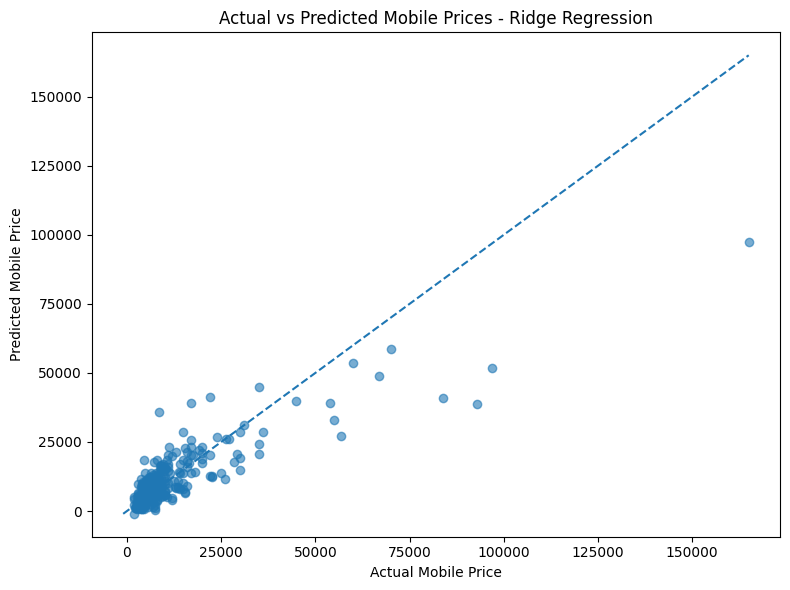

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, ridge_predictions, alpha=0.6)

plt.xlabel("Actual Mobile Price")
plt.ylabel("Predicted Mobile Price")
plt.title("Actual vs Predicted Mobile Prices - Ridge Regression")

# Reference line
min_price = min(y_test.min(), ridge_predictions.min())
max_price = max(y_test.max(), ridge_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.tight_layout()
plt.show()

Cross Validation

In [17]:
import numpy as np
import pandas as pd

from sklearn.model_selection import KFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

# 5-fold cross-validation on training data
kf = KFold(n_splits=5, shuffle=True, random_state=42)

fold_results = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X_train), start=1):

    # Split raw training data into fold-training and validation data
    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    # Fit encoder only on this fold's training data
    if categorical_features:
        fold_encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )

        train_cat = fold_encoder.fit_transform(
            X_fold_train[categorical_features]
        )
        val_cat = fold_encoder.transform(
            X_fold_val[categorical_features]
        )

        cat_columns = fold_encoder.get_feature_names_out(
            categorical_features
        )

        train_cat = pd.DataFrame(train_cat, columns=cat_columns)
        val_cat = pd.DataFrame(val_cat, columns=cat_columns)
    else:
        train_cat = pd.DataFrame(index=range(len(train_idx)))
        val_cat = pd.DataFrame(index=range(len(val_idx)))

    # Fit scaler only on this fold's training data
    if numerical_features:
        fold_scaler = StandardScaler()

        train_num = fold_scaler.fit_transform(
            X_fold_train[numerical_features]
        )
        val_num = fold_scaler.transform(
            X_fold_val[numerical_features]
        )

        train_num = pd.DataFrame(
            train_num, columns=numerical_features
        )
        val_num = pd.DataFrame(
            val_num, columns=numerical_features
        )
    else:
        train_num = pd.DataFrame(index=range(len(train_idx)))
        val_num = pd.DataFrame(index=range(len(val_idx)))

    # Combine processed features
    X_fold_train_processed = pd.concat(
        [train_num.reset_index(drop=True),
         train_cat.reset_index(drop=True)], axis=1
    )

    X_fold_val_processed = pd.concat(
        [val_num.reset_index(drop=True),
         val_cat.reset_index(drop=True)], axis=1
    )

    X_fold_val_processed = X_fold_val_processed.reindex(
        columns=X_fold_train_processed.columns,
        fill_value=0
    )

    # Train Ridge Regression with its current default alpha
    fold_model = Ridge(alpha=1.0)
    fold_model.fit(X_fold_train_processed, y_fold_train)

    # Validate this fold
    predictions = fold_model.predict(X_fold_val_processed)

    rmse = np.sqrt(mean_squared_error(y_fold_val, predictions))
    r2 = r2_score(y_fold_val, predictions)

    fold_results.append({
        "Fold": fold,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Display fold-wise results
cv_results_df = pd.DataFrame(fold_results)

print("5-Fold Cross-Validation Results — Ridge Regression")
display(cv_results_df.round(3))

print("Mean CV RMSE:", round(cv_results_df["RMSE"].mean(), 3))
print("Mean CV R2:", round(cv_results_df["R2 Score"].mean(), 3))
print("RMSE Standard Deviation:", round(cv_results_df["RMSE"].std(), 3))

5-Fold Cross-Validation Results — Ridge Regression


,Fold,RMSE,R2 Score
0,1,6645.479,0.677
1,2,7468.834,0.612
2,3,12009.172,0.485
3,4,7976.592,0.557
4,5,7978.016,0.610


Mean CV RMSE: 8415.619
Mean CV R2: 0.588
RMSE Standard Deviation: 2081.325


Hyperparameter Tuning

In [18]:
import numpy as np
import pandas as pd
import joblib

from sklearn.model_selection import KFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

# 1. Define alpha values to test
alpha_values = [0.001, 0.01, 0.1, 1, 10, 100, 1000]

# 2. Use 5-fold cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

tuning_results = []

for alpha in alpha_values:
    fold_rmses = []
    fold_r2_scores = []

    for train_idx, val_idx in kf.split(X_train):
        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]
        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        # Encode categorical features using fold-training data only
        if categorical_features:
            fold_encoder = OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )

            train_cat = fold_encoder.fit_transform(
                X_fold_train[categorical_features]
            )
            val_cat = fold_encoder.transform(
                X_fold_val[categorical_features]
            )

            cat_columns = fold_encoder.get_feature_names_out(
                categorical_features
            )

            train_cat = pd.DataFrame(
                train_cat, columns=cat_columns
            )
            val_cat = pd.DataFrame(
                val_cat, columns=cat_columns
            )
        else:
            train_cat = pd.DataFrame(index=range(len(train_idx)))
            val_cat = pd.DataFrame(index=range(len(val_idx)))

        # Scale numerical features using fold-training data only
        if numerical_features:
            fold_scaler = StandardScaler()

            train_num = fold_scaler.fit_transform(
                X_fold_train[numerical_features]
            )
            val_num = fold_scaler.transform(
                X_fold_val[numerical_features]
            )

            train_num = pd.DataFrame(
                train_num, columns=numerical_features
            )
            val_num = pd.DataFrame(
                val_num, columns=numerical_features
            )
        else:
            train_num = pd.DataFrame(index=range(len(train_idx)))
            val_num = pd.DataFrame(index=range(len(val_idx)))

        # Combine features
        X_fold_train_processed = pd.concat(
            [
                train_num.reset_index(drop=True),
                train_cat.reset_index(drop=True)
            ],
            axis=1
        )

        X_fold_val_processed = pd.concat(
            [
                val_num.reset_index(drop=True),
                val_cat.reset_index(drop=True)
            ],
            axis=1
        )

        X_fold_val_processed = X_fold_val_processed.reindex(
            columns=X_fold_train_processed.columns,
            fill_value=0
        )

        # Train Ridge using the current alpha
        ridge = Ridge(alpha=alpha)
        ridge.fit(X_fold_train_processed, y_fold_train)

        predictions = ridge.predict(X_fold_val_processed)

        fold_rmses.append(
            np.sqrt(mean_squared_error(y_fold_val, predictions))
        )
        fold_r2_scores.append(
            r2_score(y_fold_val, predictions)
        )

    tuning_results.append({
        "Alpha": alpha,
        "Mean CV RMSE": np.mean(fold_rmses),
        "Mean CV R2": np.mean(fold_r2_scores)
    })

# 3. Compare results
tuning_df = pd.DataFrame(tuning_results)
tuning_df = tuning_df.sort_values(
    "Mean CV RMSE"
).reset_index(drop=True)

display(tuning_df.round(3))

# 4. Select the best alpha
best_alpha = tuning_df.loc[0, "Alpha"]

print("Best Alpha:", best_alpha)
print("Best Mean CV RMSE:", round(tuning_df.loc[0, "Mean CV RMSE"], 3))
print("Best Mean CV R2:", round(tuning_df.loc[0, "Mean CV R2"], 3))

# 5. Train the tuned model on all training data
tuned_ridge_model = Ridge(alpha=best_alpha)
tuned_ridge_model.fit(X_train_processed, y_train)

# 6. Evaluate once on the untouched test set
tuned_predictions = tuned_ridge_model.predict(X_test_processed)

test_rmse = np.sqrt(mean_squared_error(y_test, tuned_predictions))
test_mae = np.mean(np.abs(y_test - tuned_predictions))
test_r2 = r2_score(y_test, tuned_predictions)

print("\nFinal Test Results")
print("MAE:", round(test_mae, 2))
print("RMSE:", round(test_rmse, 2))
print("R2 Score:", round(test_r2, 3))

,Alpha,Mean CV RMSE,Mean CV R2
0,1.000,8415.619,0.588
1,0.100,8435.104,0.587
2,0.010,8441.548,0.586
3,0.001,8442.306,0.586
4,10.000,8600.982,0.569
5,100.000,9218.229,0.504
6,1000.000,10020.433,0.414


Best Alpha: 1.0
Best Mean CV RMSE: 8415.619
Best Mean CV R2: 0.588

Final Test Results
MAE: 4856.34
RMSE: 8769.27
R2 Score: 0.709


In [19]:
import joblib
import json
import os

# Create a folder for saved model files
os.makedirs("saved_model", exist_ok=True)

# Save the best model based on RMSE
joblib.dump(ridge_model, "saved_model/mobile_price_model.pkl")

# Save preprocessing objects
joblib.dump(encoder, "saved_model/encoder.pkl")
joblib.dump(scaler, "saved_model/scaler.pkl")

# Save feature information for the app
model_info = {
    "categorical_features": categorical_features,
    "numerical_features": numerical_features,
    "encoded_columns": list(X_train_processed.columns)
}

with open("saved_model/model_info.json", "w") as file:
    json.dump(model_info, file, indent=4)

print("Model and preprocessing files saved successfully!")

Model and preprocessing files saved successfully!


In [20]:
import shutil
from google.colab import files

shutil.make_archive("mobile_price_model_files", "zip", "saved_model")
files.download("mobile_price_model_files.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
!pip install gradio joblib scikit-learn pandas

In [22]:
!pip install -q gradio joblib scikit-learn pandas

import gradio as gr
import joblib
import json
import pandas as pd
import numpy as np

# =========================
# 1. LOAD SAVED FILES
# =========================

model = joblib.load("saved_model/mobile_price_model.pkl")
encoder = joblib.load("saved_model/encoder.pkl")
scaler = joblib.load("saved_model/scaler.pkl")

with open("saved_model/model_info.json", "r") as f:
    model_info = json.load(f)

categorical_features = model_info["categorical_features"]
numerical_features = model_info["numerical_features"]
encoded_columns = model_info["encoded_columns"]

# Load dataset to create dropdown options
df = pd.read_csv("Mobilephone_data_final.csv")

# Use the same input column order as training
input_features = categorical_features + numerical_features

# =========================
# 2. CREATE DROPDOWN OPTIONS
# =========================

category_options = {}

for i, feature in enumerate(categorical_features):
    category_options[feature] = [
        str(value) for value in encoder.categories_[i]
    ]

numerical_options = {}

for feature in numerical_features:
    values = pd.to_numeric(df[feature], errors="coerce").dropna()
    numerical_options[feature] = sorted(values.unique().tolist())

# =========================
# 3. PRICE PREDICTION FUNCTION
# =========================

def predict_price(*values):
    try:
        input_data = pd.DataFrame(
            [values],
            columns=input_features
        )

        # Ensure numerical values are numeric
        for feature in numerical_features:
            input_data[feature] = pd.to_numeric(
                input_data[feature], errors="coerce"
            )

        if input_data.isnull().any().any():
            return "Please select a valid value for every feature."

        # Encode categorical features
        if categorical_features:
            encoded_array = encoder.transform(
                input_data[categorical_features]
            )

            encoded_df = pd.DataFrame(
                encoded_array,
                columns=encoder.get_feature_names_out(
                    categorical_features
                )
            )
        else:
            encoded_df = pd.DataFrame(index=[0])

        # Scale numerical features
        if numerical_features:
            scaled_array = scaler.transform(
                input_data[numerical_features]
            )

            scaled_df = pd.DataFrame(
                scaled_array,
                columns=numerical_features
            )
        else:
            scaled_df = pd.DataFrame(index=[0])

        # Combine in the exact training order
        processed_data = pd.concat(
            [scaled_df, encoded_df], axis=1
        )

        processed_data = processed_data.reindex(
            columns=encoded_columns,
            fill_value=0
        )

        # Predict
        prediction = float(model.predict(processed_data)[0])

        print("Raw prediction:", prediction)
        print("Selected inputs:", input_data.to_dict(orient="records"))

        return f"Estimated Mobile Price: ₹{prediction:,.2f}"

    except Exception as e:
        return f"Prediction error: {str(e)}"

# =========================
# 4. BUILD GRADIO INTERFACE
# =========================

with gr.Blocks(
    theme=gr.themes.Soft(),
    title="Mobile Price Predictor"
) as demo:

    gr.Markdown(
        """
        # 📱 Mobile Price Prediction
        ### Machine Learning Based Price Estimation

        Select the mobile specifications from the dropdowns
        and click **Predict Price**.
        """
    )

    input_components = []

    # Categorical inputs
    if categorical_features:
        gr.Markdown("## 🏷️ Brand and Categorical Specifications")

        with gr.Row():
            for feature in categorical_features:
                options = category_options[feature]

                component = gr.Dropdown(
                    choices=options,
                    value=options[0] if options else None,
                    label=feature,
                    interactive=True
                )

                input_components.append(component)

    # Numerical inputs
    if numerical_features:
        gr.Markdown("## ⚙️ Numerical Specifications")

        with gr.Row():
            for feature in numerical_features:
                options = numerical_options[feature]

                component = gr.Dropdown(
                    choices=options,
                    value=options[0] if options else None,
                    label=feature,
                    interactive=True
                )

                input_components.append(component)

    predict_button = gr.Button(
        "🔍 Predict Price",
        variant="primary"
    )

    output = gr.Textbox(
        label="💰 Predicted Mobile Price",
        interactive=False
    )

    predict_button.click(
        fn=predict_price,
        inputs=input_components,
        outputs=output
    )



demo.launch(share=True)

/tmp/ipykernel_2164/1906778191.py:120: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5b49e559b70a3e7c69.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
